In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text
from src import config as C
from src.db_utils import run_sql_file

run_sql_file("08_kpi_report.sql")
engine = C.get_engine()
ORDER = ["naive", "forecast_no_ss", "forecast_ss"]

kpi = pd.read_sql(text("SELECT * FROM v_kpi_policy"), engine).set_index("policy").loc[ORDER]
print(kpi, "\n")
kpi.to_csv(C.OUT_DIR / "08_kpi_policy.csv")

abc = pd.read_sql(text("SELECT * FROM v_kpi_abc"), engine)
print(abc.pivot(index="abc_class", columns="policy", values="total_cost")[ORDER])

                fill_rate  stockout_days  avg_inventory_units   holding  \
policy                                                                    
naive              0.9938         2292.0             393756.0  235186.0   
forecast_no_ss     0.9968         1522.0             393456.0  235028.0   
forecast_ss        0.9997          189.0             412290.0  247959.0   

                ordering  stockout     total  
policy                                        
naive           233229.0  180591.0  649006.0  
forecast_no_ss  233998.0   92649.0  561675.0  
forecast_ss     235606.0    8864.0  492429.0   

policy        naive  forecast_no_ss  forecast_ss
abc_class                                       
A          482144.0        406351.0     345647.0
B          113906.0        105071.0      98791.0
C           52956.0         50253.0      47991.0


In [2]:
comp = pd.read_sql(text("""SELECT policy, SUM(holding_cost + ordering_cost) AS fixed,
                                  SUM(stockout_cost) AS stock
                           FROM sim_results GROUP BY policy"""), engine).set_index("policy").loc[ORDER]

mults = [0, 0.25, 0.5, 1, 2, 3, 5]
# stock-out cost scales linearly with the multiplier (simulation ran at C.STOCKOUT_PENALTY_MULT)
sens = pd.DataFrame({m: comp["fixed"] + comp["stock"] / C.STOCKOUT_PENALTY_MULT * m
                     for m in mults}).round(0)
print(sens)
sens.to_csv(C.OUT_DIR / "08_penalty_sensitivity.csv")

                    0.00      0.25      0.50      1.00      2.00       3.00  \
policy                                                                        
naive           468415.0  513563.0  558711.0  649006.0  829597.0  1010188.0   
forecast_no_ss  469026.0  492188.0  515350.0  561675.0  654324.0   746973.0   
forecast_ss     483565.0  485781.0  487997.0  492429.0  501293.0   510157.0   

                     5.00  
policy                     
naive           1371370.0  
forecast_no_ss   932270.0  
forecast_ss      527884.0  


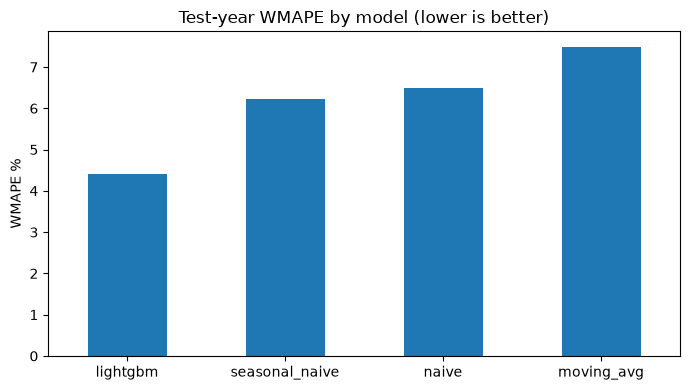

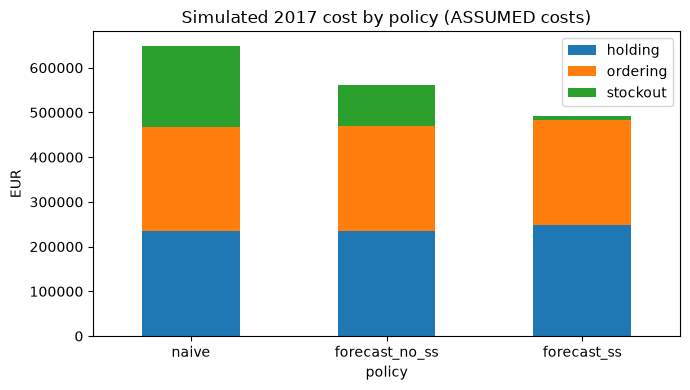

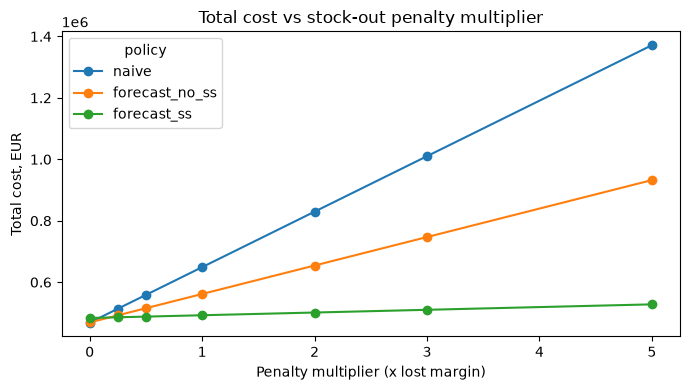

In [3]:
OUT = C.OUT_DIR

# Chart 1: forecast accuracy by model
m = pd.read_csv(OUT / "04_model_metrics.csv", index_col=0).sort_values("WMAPE")
ax = (m["WMAPE"] * 100).plot.bar(figsize=(7, 4), rot=0)
ax.set_title("Test-year WMAPE by model (lower is better)"); ax.set_ylabel("WMAPE %")
plt.tight_layout(); plt.savefig(OUT / "08_chart1_wmape.png", dpi=150); plt.show()

# Chart 2: where the cost comes from, by policy
ax = kpi[["holding", "ordering", "stockout"]].plot.bar(stacked=True, figsize=(7, 4), rot=0)
ax.set_title("Simulated 2017 cost by policy (ASSUMED costs)"); ax.set_ylabel("EUR")
plt.tight_layout(); plt.savefig(OUT / "08_chart2_cost.png", dpi=150); plt.show()

# Chart 3: does the ranking survive a different stock-out penalty?
ax = sens.T.plot(marker="o", figsize=(7, 4))
ax.set_title("Total cost vs stock-out penalty multiplier")
ax.set_xlabel("Penalty multiplier (x lost margin)"); ax.set_ylabel("Total cost, EUR")
plt.tight_layout(); plt.savefig(OUT / "08_chart3_sensitivity.png", dpi=150); plt.show()

In [4]:
print(summary[["demand", "unmet"]].round(1))

NameError: name 'summary' is not defined

In [5]:
check = pd.read_sql(text("""SELECT policy,
                                   ROUND(SUM(demand_units), 1) AS demand,
                                   ROUND(SUM(unmet_units), 1)  AS unmet
                            FROM sim_results GROUP BY policy"""), engine)
print(check)

           policy      demand    unmet
0  forecast_no_ss  10710031.0  34757.9
1     forecast_ss  10710031.0   3223.9
2           naive  10710031.0  66474.9
